# RateBeer: Predicting the Overall Score a Reviewer Will Give a Beer

Summary: Using 2.86 million RateBeer reviews, ranging from 2000 to 2012, we predict the overall score, ranging from 1-20, that a user will give a beer using information that we were given prior to the review. We train on the oldest 80% of reviews and test on the newest 10%. We use bias models with added beer information, time and a user x style offset, and a latent factor model. Our best model reachest test MSE of 5.40, which is 41% lower than predicting the predicting the average. Critical information for solving this was the type of beer it is, its style and brewer, and how the user rates that style. New users are still the hardest.

Our table of contents:

*   Predictive Task and Evaluation Plan
*   Cleaning and Exploratory Analysis of the Data
*   Modeling
*   Evaluation
*   Related work
*   Conclusions



## Predictive Task and Evaluation Plan

Our task is to predict the overall score, 1-20, that a reviewer will give a beer by just using the information available prior to when the review is written. That includes who the reviewer is and how they rated other beers, the type of beer (its past ratings, style, brewer and ABV), and the date the review happens and the number of reviews the user has written.  

What we don't use includes the appearance, aroma, palate, and taste scores. The reviewer enters them at the same time as the overall score, so they don't exist for a beer the person hasn't tried yet. We also don't use the review text because similarly, it is written after trying the beer. We look at this review data though later to see how much of the score is shown in the review.

We evaluate using:


*   Metric: MSE on the 1 to 20 scale, and the fraction of variance unexplained.
*   Split by time: The oldest 80% of reviews for training, then the next 10 for validation, and the newest 10 for testing.
*   Baselines: We predict the training average, the beer's or user's average, and the bias only model with one offset for every user and beer.
*   Our models include the bias model with added beer information, a time and user x style offset, and a latent factor model on top all.   
*   We then compare feature representations where we add one group of information at a time and measure the change in validation MSE. In another comparison we look at text representations.  



To check that the results are valid, we:


*   Remove duplicate reviews before splitting.  
*   Ensure the models learn from training reviews only.
*   Ensure every model is scored on same test set.
*   Check there is 95% boostrap confidence intervals for the difference between models.
*   Report errors for new or rare and frequent users and beers, since heavy users dominate the overall MSE.



## Cleaning and Exploratory Analysis of the Data

In [1]:
import gzip, html, os, time, string

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

main_color, second_color, text_color = "royalblue", "orange", "dimgray"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "gainsboro",
})

### Data Information

*   Our dataset came from the Ratebeer.txt.gz file from our professors dataset page.
*   A review contains a beer name, beer ID, brewer ID, ABV, style, a date, the reviewers profile name, the review text, and 5 scores. There is appearance (out of 5), aroma (out of 10), palate (out of 5), taste (out of 10), and the overall (out of 20). The 5 add up to 50 points and then divided by 10 to get a final rating out of 5.
*   This data was collected for for research on reviews that rate several aspects of a product (McAuley, Leskovec & Jurafsky, "Learning attitudes and attributes from multi-aspect reviews", ICDM 2012) and on how reviewers' tastes change as they gain experience (McAuley & Leskovec, "From amateurs to connoisseurs", WWW 2013).
*   The dataset page says this has 2,855,232 reviews, 40,213 users and 110,419 beers, April 2000 to November 2011. Our own counts are shown later.




In [2]:
import os
if "google.colab" in str(get_ipython()):
    from google.colab import drive
    drive.mount("/content/drive")
    !cp "/content/drive/MyDrive/Ratebeer.txt.gz" /content/Ratebeer.txt.gz
print("found data", os.path.exists("Ratebeer.txt.gz"))

found data True


In [3]:
DATA_PATH = "Ratebeer.txt.gz"

field_names = {
    "beer/name": "beer_name", "beer/beerId": "beer_id", "beer/brewerId": "brewer_id",
    "beer/ABV": "abv", "beer/style": "beer_style", "review/appearance": "appearance",
    "review/aroma": "aroma", "review/palate": "palate", "review/taste": "taste",
    "review/overall": "overall", "review/time": "time", "review/profileName": "user",
    "review/text": "text",
}
column_values = {name: [] for name in field_names.values()}
shared_copy = {}
record, incomplete_records = {}, 0

def save_record(record):
    global incomplete_records
    if len(record) != len(field_names):
        incomplete_records += 1
        return
    for column_name, value in record.items():
        if column_name != "text":
            value = shared_copy.setdefault(value, value)
        column_values[column_name].append(value)

# Is plain text with one "key: value" line per field and also Latin1 encoded
with gzip.open(DATA_PATH, "rt", encoding="latin-1") as file:
    for line in file:
        line = line.rstrip("\n")
        if line == "":
            if record:
                save_record(record)
                record = {}
            continue
        key, _, value = line.partition(": ")
        if key in field_names:
            record[field_names[key]] = value.strip()
    if record:
        save_record(record)

df = pd.DataFrame(column_values)
del column_values, shared_copy

print(f"Reviews loaded: {len(df):,} | incomplete records skipped: {incomplete_records} ")
display(df.head(3))

Reviews loaded: 2,924,163 | incomplete records skipped: 0 


,beer_name,beer_id,brewer_id,abv,beer_style,appearance,aroma,palate,taste,overall,time,user,text
0,John Harvards Simcoe IPA,63836,8481,5.4,India Pale Ale &#40;IPA&#41;,4/5,6/10,3/5,6/10,13/20,1157587200,hopdog,"On tap at the Springfield, PA location. Poured..."
1,John Harvards Simcoe IPA,63836,8481,5.4,India Pale Ale &#40;IPA&#41;,4/5,6/10,4/5,7/10,13/20,1157241600,TomDecapolis,On tap at the John Harvards in Springfield PA....
2,John Harvards Cristal Pilsner,71716,8481,5,Bohemian Pilsener,4/5,5/10,3/5,6/10,14/20,958694400,PhillyBeer2112,"UPDATED: FEB 19, 2003 Springfield, PA. I've ne..."


Every review was read fully and every field including numbers are strings which need to be converted.

### Cleaning Data

Missing values!

isnull() only sees the None and NaN so some other empty values such as '-' or an empty string '' was not found.  
To fix this, we:
*   count what isnull() reports first.
*   scan every column for values that are empty, made only of symbols, or common empty words such as n/a or null,and convert the real placeholders to NaN

In [4]:
print("Missing values from isnull() is ", df.isnull().sum().sum())
null_words = ["n/a", "na", "null", "none", "nan", "unknown", "missing"]
scan_rows = []
for column_name in df.columns:
    values = df[column_name].str.strip()
    scan_rows.append({"column": column_name,
                      "empty": (values == "").sum(),
                      "symbols only": (~values.str.contains(r"[A-Za-z0-9]") & (values != "")).sum(),
                      "missing words": values.str.lower().isin(null_words).sum()})
scan = pd.DataFrame(scan_rows).set_index("column")
display(scan[scan.sum(axis=1) > 0])
system_messages = [
    "(This beer rating was imported from FB and unfortunately lacks any further comments.)",
    "Imported from Beerseek, no description given with original rating. Need to re-rate beer.",
]
no_letters = ~df["text"].str.contains(r"[A-Za-z]")
import_message = df["text"].str.strip().isin(system_messages)
print("Texts with no letters is ", no_letters.sum(), " and the import messages is ", import_message.sum(),
      " and the reviews by a user named 'missing' is ", (df["user"] == "missing").sum())
df["abv"] = df["abv"].replace("-", np.nan)
df.loc[no_letters | import_message, "text"] = np.nan
missing = df.isnull().sum()
pd.DataFrame({"missing": missing, "% of reviews": (missing / len(df) * 100).round(2)})[missing > 0]

Missing values from isnull() is  0


,empty,symbols only,missing words
column,,,
abv,0,138637,0
user,0,0,68
text,5002,86,0


Texts with no letters is  5110  and the import messages is  75  and the reviews by a user named 'missing' is  68


,missing,% of reviews
abv,138637,4.74
text,5185,0.18


Before cleaning, isnull() shows 0 missing values, but the scan finds hidden ones. The abv column has reviews with '-'. The text column has reviews that are empty or contain only symbols, and some are automatic messages saying the review has no comments. The user column has a profile literally named 'missing', but its reviews look like a real user's, so we keep it. After cleaning, pandas sees 138,637 missing ABVs and 5,185 missing texts.

#### Now we convert the text to numbers and dates

In [5]:
for column_name in ["appearance", "aroma", "palate", "taste", "overall"]:
    values = df[column_name].unique()
    score_of = {value: int(value.split("/")[0]) for value in values}
    maximums = {int(value.split("/")[1]) for value in values}
    df[column_name] = df[column_name].map(score_of)
    print(column_name, "maximum:", maximums, "| range:", df[column_name].min(), "to", df[column_name].max())

df["abv"] = pd.to_numeric(df["abv"])
df["time"] = pd.to_numeric(df["time"])
df["date"] = pd.to_datetime(df["time"], unit="s")
print("Dates:", df["date"].min().date(), "to", df["date"].max().date(),
      "| timestamps not at midnight:", (df["time"] % 86400 != 0).sum())
print("ABV range:", df["abv"].min(), "to", df["abv"].max())

appearance maximum: {5} | range: 1 to 5
aroma maximum: {10} | range: 1 to 10
palate maximum: {5} | range: 1 to 5
taste maximum: {10} | range: 1 to 10
overall maximum: {20} | range: 1 to 20
Dates: 2000-04-12 to 2012-01-13 | timestamps not at midnight: 0
ABV range: 0.01 to 57.7


- Every score has the form score/maximum, and no score falls outside its range.
- Every timestamp is exactly midnight, so we know the date of a review but not the time of day.
- ABV runs from 0.01% to 57.7%. These are real beers (alcohol free beers and an extreme eisbock), so nothing is removed.

#### HTML codes in names, styles and text

Names and styles contain web codes such as `&#40;` for "(". We decode them with `html.unescape`. Accented letters such as "Kölsch" fine.

In [6]:
html_code_pattern = r"&#?[A-Za-z0-9]+;"
print("Reviews with HTML codes include", df["beer_name"].str.contains(html_code_pattern).sum(),
      "names,", df["beer_style"].str.contains(html_code_pattern).sum(),
      "styles and", df["text"].str.contains(html_code_pattern, na=False).sum(), "texts")

for column_name in ["beer_name", "beer_style"]:
    cleaned_value_of = {value: html.unescape(value) for value in df[column_name].unique()}
    df[column_name] = df[column_name].map(cleaned_value_of)
text_has_code = df["text"].str.contains(html_code_pattern, na=False)
df.loc[text_has_code, "text"] = df.loc[text_has_code, "text"].apply(html.unescape)

print("Example", df.loc[0, "beer_style"])

Reviews with HTML codes include 214417 names, 234046 styles and 4547 texts
Example India Pale Ale (IPA)


#### Duplicates


In [7]:
pair_columns = ["user", "beer_id"]
print("Number of exact duplicate rows is ", df.duplicated().sum(),
      "and the extra copies of a (user, beer) pair is", df.duplicated(subset=pair_columns).sum())

# Figure out what differs
repeated = df[df.duplicated(subset=pair_columns, keep=False)].groupby(pair_columns)
for column_name in ["brewer_id", "overall", "text", "date"]:
    print("pairs whose copies differ in", column_name, ":", (repeated[column_name].nunique(dropna=False) > 1).sum())

df = df.drop_duplicates(subset=pair_columns).reset_index(drop=True)
print("Reviews after removing copies:", len(df))

Number of exact duplicate rows is  4 and the extra copies of a (user, beer) pair is 68931
pairs whose copies differ in brewer_id : 68926
pairs whose copies differ in overall : 1
pairs whose copies differ in text : 2
pairs whose copies differ in date : 0
Reviews after removing copies: 2855232


Only 4 rows are exact copies, but 68,931 reviews appear twice, identical except for the brewer ID. These beers are listed under two brewers, so each review was collected once from each brewer's page. We keep the first copy, so no review can appear in both training and test.

This leaves 2,855,232 reviews, exactly the number on the dataset page, which confirms the duplicates were collection artifacts.

### Basic statistics

In [8]:
reviews_per_user = df["user"].value_counts()
reviews_per_beer = df["beer_id"].value_counts()
df["word_count"] = df["text"].str.count(r"\S+")
density = len(df) / (df["user"].nunique() * df["beer_id"].nunique()) * 100

pd.DataFrame({"value": [
    f"{len(df):,}", f"{df['user'].nunique():,}", f"{df['beer_id'].nunique():,}", f"{df['brewer_id'].nunique():,}",
    f"{df['beer_style'].nunique()}", f"{df['date'].min().date()} to {df['date'].max().date()}",
    f"{df['word_count'].median():.0f}", f"{density:.3f}%",
]}, index=["reviews", "users (profile names)", "beers", "brewers", "styles", "dates",
           "median words per review", "density: reviews / (users x beers)"])

,value
reviews,"2,855,232"
users (profile names),"29,265"
beers,"110,369"
brewers,"7,424"
styles,89
dates,2000-04-12 to 2012-01-13
median words per review,44
density: reviews / (users x beers),0.088%


*   We have fewer users than the dataset page (29,265 vs. 40,213) because the file only has profile names and not user IDs.
*   Only 0.088% of all possible (user, beer) pairs have a review, so user-beer rating matrix is extremely sparse.

Our target is the overall score.

mean 13.24 | variance 11.07 | skew -1.03
share of scores from 12 to 17: 71.0%


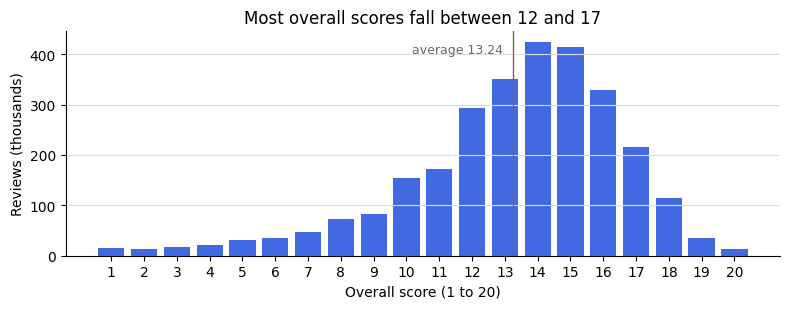

In [9]:
overall_counts = df["overall"].value_counts().sort_index()
overall_mean = df["overall"].mean()
overall_variance = ((df["overall"] - overall_mean) ** 2).mean()
print(f"mean {overall_mean:.2f} | variance {overall_variance:.2f} | skew {df['overall'].skew():.2f}")
print(f"share of scores from 12 to 17: {df['overall'].between(12, 17).mean() * 100:.1f}%")

figure, axis = plt.subplots(figsize=(8, 3.2))
axis.bar(overall_counts.index, overall_counts.values / 1000, color=main_color, width=0.8)
axis.axvline(overall_mean, color=text_color, linewidth=1)
axis.text(overall_mean - 0.3, overall_counts.max() / 1000 * 0.95, f"average {overall_mean:.2f}", ha="right", color=text_color, fontsize=9)
axis.set_xticks(range(1, 21))
axis.set_xlabel("Overall score (1 to 20)")
axis.set_ylabel("Reviews (thousands)")
axis.set_title("Most overall scores fall between 12 and 17")
axis.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

The average overall score is 13.24, and 71% of scores fall between 12 and 17. The distribution leans left with a skew of -1.03. Low scores trail off in a long tail while top scores are rare. Always predicting the average gives an MSE equal to the variance of 11.07.

### Patterns

users: % of users {'1': 32.8, '2-5': 27.5, '6-10': 9.5, '11-50': 14.0, '51-100': 3.9, '101-500': 7.7, '501-1000': 2.1, 'over 1000': 2.5}
users: % of reviews {'1': 0.3, '2-5': 0.8, '6-10': 0.8, '11-50': 3.2, '51-100': 2.9, '101-500': 18.0, '501-1000': 15.0, 'over 1000': 59.0}
beers: % of beers {'1': 22.5, '2-5': 34.0, '6-10': 14.5, '11-50': 20.9, '51-100': 3.7, '101-500': 3.7, '501-1000': 0.6, 'over 1000': 0.3}
beers: % of reviews {'1': 0.9, '2-5': 4.1, '6-10': 4.3, '11-50': 17.9, '51-100': 10.1, '101-500': 30.3, '501-1000': 15.8, 'over 1000': 16.7}


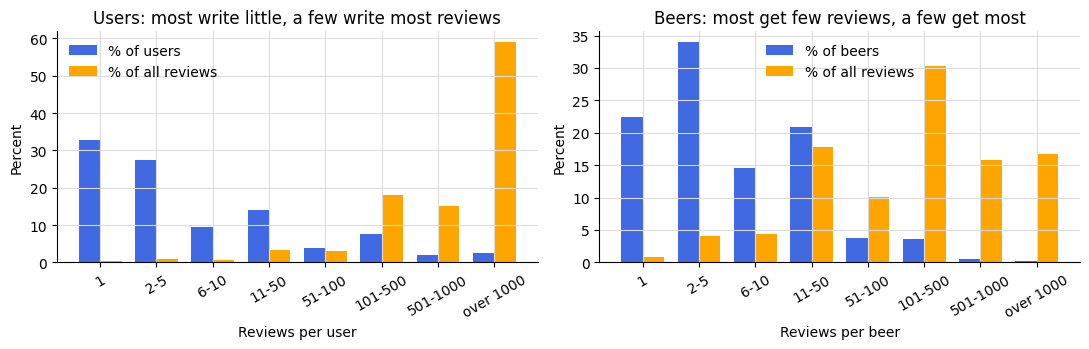

In [10]:
bucket_edges = [0, 1, 5, 10, 50, 100, 500, 1000, 100000]
bucket_labels = ["1", "2-5", "6-10", "11-50", "51-100", "101-500", "501-1000", "over 1000"]
bar_positions = np.arange(len(bucket_labels))

figure, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for axis, counts, group_label in [(axes[0], reviews_per_user, "users"), (axes[1], reviews_per_beer, "beers")]:
    bucket = pd.cut(counts, bins=bucket_edges, labels=bucket_labels)
    share_of_group = bucket.value_counts(normalize=True).sort_index() * 100
    share_of_reviews = counts.groupby(bucket, observed=False).sum() / len(df) * 100
    print(f"{group_label}: % of {group_label}", share_of_group.round(1).to_dict())
    print(f"{group_label}: % of reviews", share_of_reviews.round(1).to_dict())
    axis.bar(bar_positions - 0.19, share_of_group.values, width=0.38, color=main_color, label="% of " + group_label)
    axis.bar(bar_positions + 0.19, share_of_reviews.values, width=0.38, color=second_color, label="% of all reviews")
    axis.set_xticks(bar_positions, bucket_labels, rotation=30)
    axis.set_xlabel("Reviews per " + group_label[:-1])
    axis.set_ylabel("Percent")
    axis.legend(frameon=False)
axes[0].set_title("Users: most write little, a few write most reviews")
axes[1].set_title("Beers: most get few reviews, a few get most")
plt.tight_layout()
plt.show()

A third of users wrote just one review, while the 4.6% who wrote over 500 produced 74% of all reviews. Similarly, 4.6% of beers received 63% of the reviews. Heavy users and popular beers dominate the MSE.

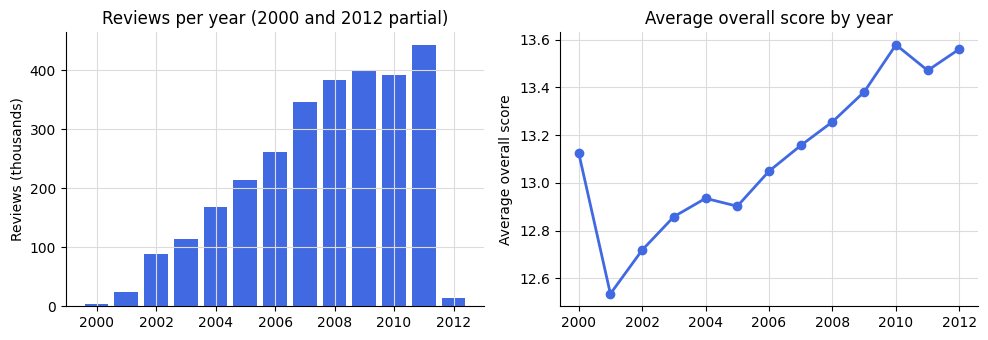

In [11]:
review_year = df["date"].dt.year
reviews_per_year = df.groupby(review_year)["overall"].count()
average_by_year = df.groupby(review_year)["overall"].mean()

figure, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].bar(reviews_per_year.index, reviews_per_year.values / 1000, color=main_color)
axes[0].set_title("Reviews per year (2000 and 2012 partial)")
axes[0].set_ylabel("Reviews (thousands)")
axes[1].plot(average_by_year.index, average_by_year.values, color=main_color, linewidth=2, marker="o")
axes[1].set_title("Average overall score by year")
axes[1].set_ylabel("Average overall score")
for axis in axes:
    axis.set_xticks(range(2000, 2013, 2))
plt.tight_layout()
plt.show()

Reviews grow to about 400,000 a year by 2009–2011, and the average score rises from about 12.5 (2001) to about 13.5 (2010–2012). A year term in the model can capture this.

### Beer style and strength

Most reviewed styles: India Pale Ale (IPA), Pale Lager, Belgian Strong Ale, Imperial Stout, Imperial/Double IPA
Lowest: {'Low Alcohol': 6.33, 'Malt Liquor': 6.81, 'Pale Lager': 7.49}
Highest: {'Abt/Quadrupel': 15.68, 'Ice Cider/Perry': 15.81, 'Imperial Stout': 15.87}


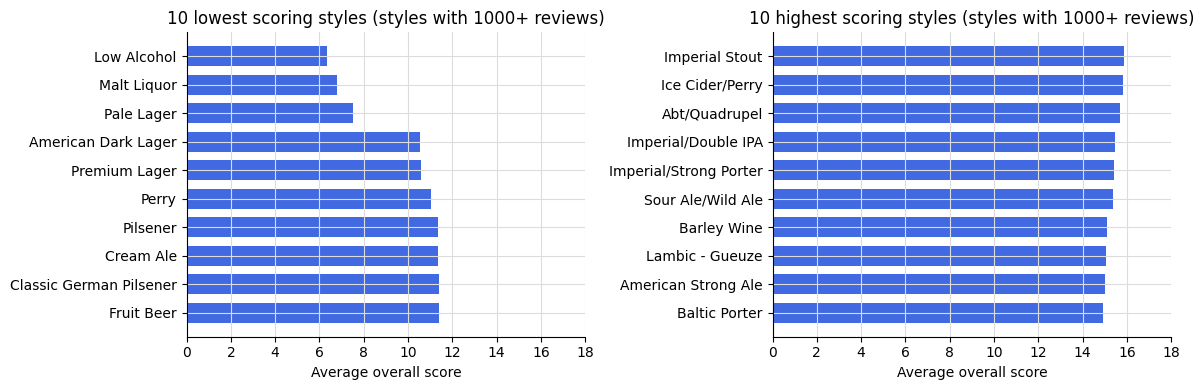

In [12]:
style_summary = df.groupby("beer_style")["overall"].agg(["mean", "count"])
common_styles = style_summary[style_summary["count"] >= 1000].sort_values("mean")
print("Most reviewed styles:", ", ".join(style_summary.sort_values("count", ascending=False).index[:5]))
print("Lowest:", common_styles["mean"].head(3).round(2).to_dict())
print("Highest:", common_styles["mean"].tail(3).round(2).to_dict())

figure, axes = plt.subplots(1, 2, figsize=(12, 4))
for axis, styles_to_plot, panel_title in [(axes[0], common_styles.head(10).iloc[::-1], "10 lowest scoring styles"),
                                          (axes[1], common_styles.tail(10), "10 highest scoring styles")]:
    axis.barh(styles_to_plot.index, styles_to_plot["mean"], color=main_color, height=0.7)
    axis.set_xlim(0, 18)
    axis.set_xlabel("Average overall score")
    axis.set_title(panel_title + " (styles with 1000+ reviews)")
plt.tight_layout()
plt.show()

Average overall by ABV range: {'0-3': 7.33, '3-4': 11.28, '4-5': 11.48, '5-6': 12.94, '6-7': 14.09, '7-8': 14.38, '8-9': 14.7, '9-10': 15.24, '10-12': 15.47, '12-15': 15.48, '15+': 15.08}


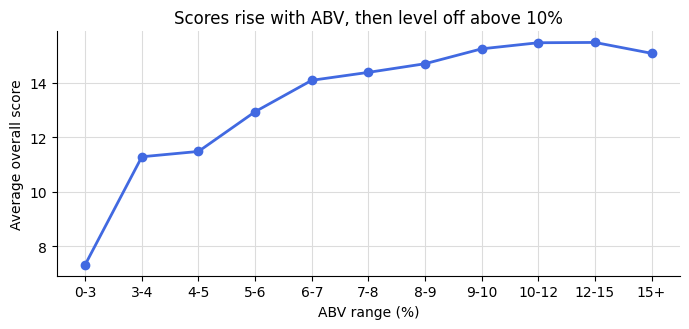

In [13]:
abv_edges = [0, 3, 4, 5, 6, 7, 8, 9, 10, 12, 15, 60]
abv_labels = ["0-3", "3-4", "4-5", "5-6", "6-7", "7-8", "8-9", "9-10", "10-12", "12-15", "15+"]
average_by_abv = df.groupby(pd.cut(df["abv"], bins=abv_edges, labels=abv_labels), observed=False)["overall"].mean()
print("Average overall by ABV range:", average_by_abv.round(2).to_dict())

figure, axis = plt.subplots(figsize=(7, 3.4))
axis.plot(abv_labels, average_by_abv.values, color=main_color, linewidth=2, marker="o")
axis.set_xlabel("ABV range (%)")
axis.set_ylabel("Average overall score")
axis.set_title("Scores rise with ABV, then level off above 10%")
plt.tight_layout()
plt.show()

*   style: averages run from about 6 (low alcohol beer, malt liquor) to almost 16 (imperial stout, quadrupel, double IPA), and IPA is the most reviewed style.
*   ABV: the average score climbs from 7.3 below 3% to about 15.5 at 10-15%, then dips slightly. Because this is a curve, not a straight line, the model uses ABV ranges instead of the raw number. Style and ABV overlap, because strong styles are high in alcohol.

In [14]:
sample = df.loc[df["text"].notnull(), ["text", "overall"]].sample(n=50000, random_state=42)
sample = sample[(sample["overall"] <= 8) | (sample["overall"] >= 17)]
words = sample["text"].str.lower().str.translate(str.maketrans("", "", string.punctuation)).str.split()
is_low = (sample["overall"] <= 8).to_numpy()
low_counts = words[is_low].explode().value_counts()
high_counts = words[~is_low].explode().value_counts()
counts = pd.DataFrame({"low": low_counts, "high": high_counts}).fillna(0)
counts = counts[counts["low"] + counts["high"] >= 50]
low_rate = counts["low"] / low_counts.sum() * 10000
high_rate = counts["high"] / high_counts.sum() * 10000
low_ratio = ((low_rate + 1) / (high_rate + 1)).sort_values(ascending=False).head(12)
high_ratio = ((high_rate + 1) / (low_rate + 1)).sort_values(ascending=False).head(12)
pd.DataFrame({"low-score word": low_ratio.index, "x more common in low reviews": low_ratio.round(1).values,
              "high-score word": high_ratio.index, "x more common in high reviews": high_ratio.round(1).values},
             index=range(1, 13))

,low-score word,x more common in low reviews,high-score word,x more common in high reviews
1,corn,18.6,bourbon,12.6
2,watery,15.8,rich,10.2
3,boring,8.6,complex,8.6
4,bland,8.5,excellent,8.2
5,water,7.8,oak,7.7
6,weak,7.6,delicious,7.3
7,cheap,7.6,chocolate,7.3
8,bad,7.4,coffee,6.7
9,skunky,7.2,balanced,6.3
10,lager,6.9,pine,6.2


Low scores bring words like corn, watery, bland, skunky and cheap; high scores bring bourbon, rich, complex, oak and delicious. The text clearly carries information about the score, so we test text based models later too.

users with 10+ reviews: 9,233, st. dev. of their averages 1.98, middle half between 12.4 and 14.8
beers with 10+ reviews: 34,477, st. dev. of their averages 2.30


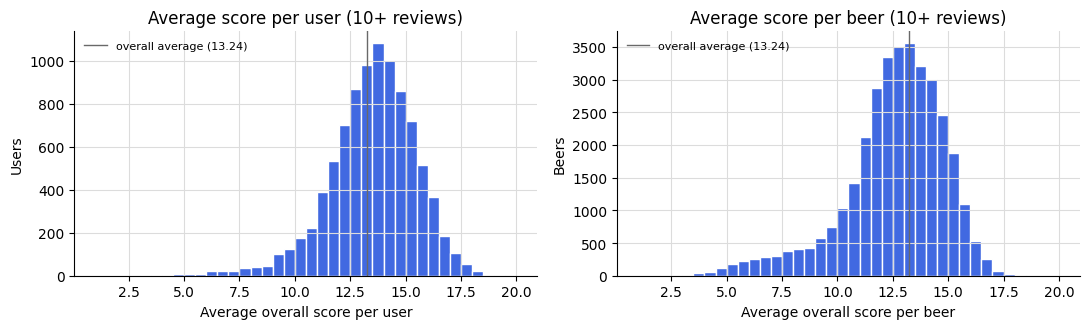

In [15]:
active_users = df.groupby("user")["overall"].agg(["mean", "count"]).query("count >= 10")["mean"]
reviewed_beers = df.groupby("beer_id")["overall"].agg(["mean", "count"]).query("count >= 10")["mean"]
print(f"users with 10+ reviews: {len(active_users):,}, st. dev. of their averages {active_users.std():.2f}, "
      f"middle half between {active_users.quantile(0.25):.1f} and {active_users.quantile(0.75):.1f}")
print(f"beers with 10+ reviews: {len(reviewed_beers):,}, st. dev. of their averages {reviewed_beers.std():.2f}")

figure, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for axis, averages, label in [(axes[0], active_users, "user"), (axes[1], reviewed_beers, "beer")]:
    axis.hist(averages, bins=np.arange(1, 20.5, 0.5), color=main_color, edgecolor="white")
    axis.axvline(overall_mean, color=text_color, linewidth=1, label=f"overall average ({overall_mean:.2f})")
    axis.set_xlabel(f"Average overall score per {label}")
    axis.set_ylabel(label.capitalize() + "s")
    axis.set_title(f"Average score per {label} (10+ reviews)")
    axis.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

Users differ in how generous they are (the middle half average between 12.4 and 14.8), and beers differ even more (standard deviation 2.30 vs. 1.98 for users). Bias model captures both with one offset per user and one per beer.

Score minus own average, by review number: {'1': 0.59, '2-5': 0.19, '6-10': 0.01, '11-25': -0.14, '26-50': -0.2, '51-100': -0.15, '101-250': -0.05, '251-500': -0.02, '501-1000': 0.01, '1001-2500': 0.05, '2500+': 0.15}


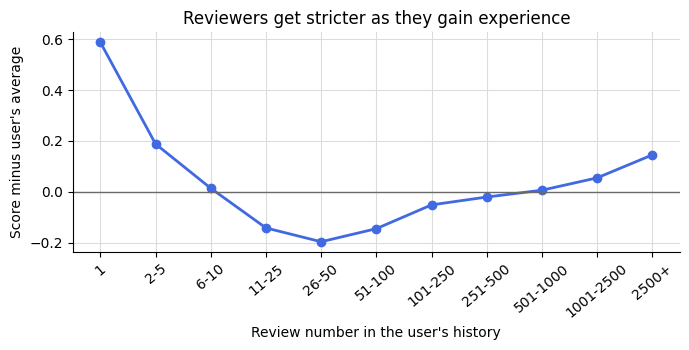

In [16]:
user_history = df[["user", "date"]].sort_values(["user", "date"], kind="stable")
df["review_number"] = user_history.groupby("user").cumcount() + 1

experience_edges = [0, 1, 5, 10, 25, 50, 100, 250, 500, 1000, 2500, 100000]
experience_labels = ["1", "2-5", "6-10", "11-25", "26-50", "51-100", "101-250", "251-500", "501-1000", "1001-2500", "2500+"]
experience_range = pd.cut(df["review_number"], bins=experience_edges, labels=experience_labels)
difference_from_own_average = df["overall"] - df.groupby("user")["overall"].transform("mean")
heavy_user_rows = df.groupby("user")["overall"].transform("count") >= 50
within_user_by_experience = difference_from_own_average[heavy_user_rows].groupby(experience_range[heavy_user_rows], observed=False).mean()
print("Score minus own average, by review number:", within_user_by_experience.round(2).to_dict())

figure, axis = plt.subplots(figsize=(7, 3.6))
axis.plot(experience_labels, within_user_by_experience.values, color=main_color, linewidth=2, marker="o")
axis.axhline(0, color=text_color, linewidth=1)
axis.set_xticks(range(len(experience_labels)), experience_labels, rotation=40)
axis.set_xlabel("Review number in the user's history")
axis.set_ylabel("Score minus user's average")
axis.set_title("Reviewers get stricter as they gain experience")
plt.tight_layout()
plt.show()

Compared with their own average, users' first reviews are about 0.6 points more generous, and reviews 11-100 are slightly harsher. People become stricter as they gain experience, so the model includes an experience term.

## Modeling

### Context

- Input: a user, a beer, and a date. We use what was known before that date (the past ratings of the user and the beer, the beer's style, brewer and ABV, and how many reviews the user had written).
- Output: the predicted overall score (ranges from 1 to 20).
- What we optimize: the squared error on the training reviews, plus a penalty (λ) so users and beers with only a few reviews don't get extreme values.

Why these models are appropriate: this is a rating prediction problem, and the EDA showed big differences between users, beers, and styles, which is what these models learn. We compare:
1. Baselines: the training average, the beer's average, or the user's average.
2. Bias models: the average plus an offset (how much higher or lower than average) for the user and for the beer, μ + β<sub>user</sub> + β<sub>beer</sub>. Then, we add offsets for style, brewer, ABV, experience, year, and user × style.
3. A latent factor model, γ<sub>user</sub> · γ<sub>beer</sub>, on top of the best bias model.
4. A side comparison: predicting the score from the review text.

Why not other models:
- Classifiers like logistic regression predict a category, but our score is a number.
- Similarity-based rating prediction did worse than the average in the class example, and it can't handle beers nobody has rated yet.
- BPR ranks which beers a user might try. It doesn't predict a score.

### Helper functions

- `shrunk_average`: a beer's or user's average, pulled toward the overall average when there are only a few reviews.
- `fit_additive` and `predict_additive`: fit and use the bias models.
- `evaluate_additive`: returns a bias model's validation MSE, which we use to pick settings.
- `train_latent_factors` and `latent_prediction`: the latent factor model.
- `record`: saves each model's MSE and keeps every prediction between 1 and 20.

Users, beers, brewers and styles are stored as numbers, so each set of offsets is an array we look up by that number.

### Step 1. Splitting the data by time

We sort the reviews by date: the oldest 80% for training, the next 10% for validation (to pick settings like λ), and the newest 10% for testing. Doing the split this way allows us to learn from the past and predict the future. 

In [17]:
import gc
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import Ridge

# Use 42 as the seed
rng = np.random.default_rng(42)

# Keep the columns the models need and sort reviews from oldest to newest
model_df = df[["user", "beer_id", "brewer_id", "beer_style", "abv", "overall", "date", "review_number", "text"]]
model_df = model_df.sort_values("date", kind="stable").reset_index(drop=True)

# Turn every user, beer, brewer, and style into a number (0, 1, 2, ...)
# u = user, i = beer (item), br = brewer, s = style
n_levels = {}
for column_name, code_name in [("user", "u"), ("beer_id", "i"), ("brewer_id", "br"), ("beer_style", "s")]:
    model_df[code_name] = model_df[column_name].astype("category").cat.codes.astype(np.int64)
    n_levels[code_name] = int(model_df[code_name].max()) + 1

# Oldest 80% is train, next 10% is validation, newest 10% is test
number_of_reviews = len(model_df)
cut_valid = int(0.8 * number_of_reviews)
cut_test = int(0.9 * number_of_reviews)
split = np.array(["train"] * cut_valid + ["valid"] * (cut_test - cut_valid) + ["test"] * (number_of_reviews - cut_test))
model_df["split"] = split

# Save a sample of review texts for the text comparison at the end
# Then, drop the text column to free memory
text_sample = {}
for part_name, sample_size in [("train", 150_000), ("valid", 30_000), ("test", 50_000)]:
    part_text = model_df.loc[split == part_name, ["text", "overall"]].dropna()
    text_sample[part_name] = part_text.sample(sample_size, random_state=42)
model_df = model_df.drop(columns="text")
del df
gc.collect()

for part_name in ["train", "valid", "test"]:
    part = model_df[split == part_name]
    print(f"{part_name:<5} {len(part):>9,} reviews | {part['date'].min().date()} to {part['date'].max().date()}"
          f" | average overall {part['overall'].mean():.2f}")

train_mask = split == "train"
valid_mask = split == "valid"
test_mask = split == "test"

# Number of training reviews for every user and every beer
train_user_count = np.bincount(model_df.loc[train_mask, "u"], minlength=n_levels["u"])
train_beer_count = np.bincount(model_df.loc[train_mask, "i"], minlength=n_levels["i"])
for part_name, mask in [("valid", valid_mask), ("test", test_mask)]:
    part = model_df[mask]
    new_users = (train_user_count[part["u"]] == 0).mean()
    new_beers = (train_beer_count[part["i"]] == 0).mean()
    print(f"{part_name}: {new_users:.1%} of reviews are by users not seen in training, "
          f"{new_beers:.1%} are of beers not seen in training")

train 2,284,185 reviews | 2000-04-12 to 2010-09-12 | average overall 13.17
valid   285,523 reviews | 2010-09-12 to 2011-05-28 | average overall 13.54
test    285,524 reviews | 2011-05-28 to 2012-01-13 | average overall 13.46
valid: 13.5% of reviews are by users not seen in training, 18.3% are of beers not seen in training
test: 23.3% of reviews are by users not seen in training, 30.4% are of beers not seen in training


- Training covers April 2000 to September 2010
- Validation covers September 2010 to May 2011
- Test covers May 2011 to January 2012

23% of test reviews are by users not seen in training, and 30% are of beers not seen in training.

### Step 2. Adding beer information and time

Each of these gets its own set of offsets:
- Experience: how many reviews the user had written (in the same 11 ranges as the EDA).
- Year: the review year (years after training use the last training year since there's no data to learn them from).
- ABV range: the EDA's ABV ranges, plus a "missing" range so we keep those reviews.
- User × style: one offset for each user and style pair (e.g., "this user likes IPAs more than usual").

This cell also sets up μ (the training average), `mse`, and `results`, which is where every model's scores are saved.

In [18]:
# Experience: which range the user's review number falls in
experience_edges = [0, 1, 5, 10, 25, 50, 100, 250, 500, 1000, 2500, np.inf]
model_df["exp"] = pd.cut(model_df["review_number"], bins=experience_edges).cat.codes.astype(np.int64)

# ABV range (pd.cut gives -1 for a missing ABV, so those reviews get their own range)
abv_edges = [0, 3, 4, 5, 6, 7, 8, 9, 10, 12, 15, 100]
abv_bin = pd.cut(model_df["abv"], bins=abv_edges).cat.codes.astype(np.int64)
model_df["abv_bin"] = np.where(abv_bin < 0, len(abv_edges) - 1, abv_bin)

# Year counted from the first year
# Years after training are treated as the last training year
year = model_df["date"].dt.year
last_train_year = int(year[train_mask].max())
model_df["year"] = (np.minimum(year, last_train_year) - year.min()).astype(np.int64)

for name in ["exp", "abv_bin", "year"]:
    n_levels[name] = int(model_df[name].max()) + 1

# One code per (user, style) pair
model_df["us"] = model_df["u"] * n_levels["s"] + model_df["s"]
n_levels["us"] = n_levels["u"] * n_levels["s"]
print("Last training year:", last_train_year)
print("Number of codes in each group:", n_levels)

# The three parts, their true scores, and the training average (mu)
train = model_df[train_mask]
valid = model_df[valid_mask]
test = model_df[test_mask]
y_train = train["overall"].to_numpy(float)
y_valid = valid["overall"].to_numpy(float)
y_test = test["overall"].to_numpy(float)
mu = y_train.mean()

def mse(y, prediction):
    return float(np.mean((y - prediction) ** 2))

# One row per model: train / valid / test MSE and fitting time
results = []
# Keep every model's test predictions
test_predictions = {}

Last training year: 2010
Number of codes in each group: {'u': 29265, 'i': 110369, 'br': 7424, 's': 89, 'exp': 11, 'abv_bin': 12, 'year': 11, 'us': 2604585}


### Step 3. Baselines

The baselines use three simple predictions: the training average for every review, the beer's average, or the user's average. When a beer or user has only a few reviews, its average is pulled toward the overall average. For example, a beer with one review of 20 gets $\frac{20 + 5 \times 13.17}{6} \approx 14.3$ instead of 20.

In [19]:
# Average training score for each beer (or user), pulled toward mu when there are only a few reviews
def shrunk_average(codes_train, y, codes_target, n_codes, strength=5):
    total = np.bincount(codes_train, weights=y, minlength=n_codes)
    count = np.bincount(codes_train, minlength=n_codes)
    return (total[codes_target] + strength * mu) / (count[codes_target] + strength)

# Keep predictions between 1 and 20, save the errors, and keep the test predictions
def record(name, train_pred, valid_pred, test_pred, seconds):
    train_pred = np.clip(train_pred, 1, 20)
    valid_pred = np.clip(valid_pred, 1, 20)
    test_pred = np.clip(test_pred, 1, 20)
    results.append({"model": name, "train MSE": mse(y_train, train_pred), "valid MSE": mse(y_valid, valid_pred),
                    "test MSE": mse(y_test, test_pred), "fit time (s)": round(seconds, 1)})
    test_predictions[name] = test_pred
    print(f"{name:<45} valid MSE {results[-1]['valid MSE']:.3f} | test MSE {results[-1]['test MSE']:.3f}")

record("Global mean", np.full(len(train), mu), np.full(len(valid), mu), np.full(len(test), mu), 0)

for label, column in [("Beer average", "i"), ("User average", "u")]:
    start_time = time.time()
    train_pred = shrunk_average(train[column].values, y_train, train[column].values, n_levels[column])
    valid_pred = shrunk_average(train[column].values, y_train, valid[column].values, n_levels[column])
    test_pred = shrunk_average(train[column].values, y_train, test[column].values, n_levels[column])
    record(label, train_pred, valid_pred, test_pred, time.time() - start_time)

Global mean                                   valid MSE 9.360 | test MSE 9.088
Beer average                                  valid MSE 5.806 | test MSE 6.096
User average                                  valid MSE 8.344 | test MSE 8.402


Knowing only the beer brings the test MSE from 9.09 down to 6.10. Knowing only the user gets it to 8.40. This means which beer it is matters more than who is rating it.

### Step 4. Bias models

The bias model predicts the average plus offsets for the user and the beer. We add the Step 2 offsets one group at a time, so the full model is:

$$\text{prediction} = \mu + \beta_{user} + \beta_{beer} + \beta_{style} + \beta_{brewer} + \beta_{ABV} + \beta_{experience} + \beta_{year} + \beta_{user \times style}$$

We fit one group at a time while holding the others fixed. Each offset is how far off the rest of the model is on that user's (or beer's) reviews, added up and divided by the number of reviews plus λ. We repeat this 10 times, and each fit takes under a second.

For example, a user whose 3 reviews were under-predicted by 2, 1, and 3 gets $\frac{6}{3 + 1} = 1.5$ with λ = 1, instead of their plain average of 2.

In [20]:
def fit_additive(groups, data, y, lam, iterations=10):
    # groups: which offset groups to use, e.g. ["u", "i", "s"]
    # lam: the regularization strength (lambda) for each group
    codes, counts, offsets, current = {}, {}, {}, {}
    for group in groups:
        codes[group] = data[group].to_numpy()
        counts[group] = np.bincount(codes[group], minlength=n_levels[group])
        offsets[group] = np.zeros(n_levels[group])
        # This group's part of every review's prediction
        current[group] = np.zeros(len(y))
    # The full prediction for every training review
    total = np.full(len(y), mu)
    for round_number in range(iterations):
        for group in groups:
            # What the model gets wrong, with this group's own part taken back out
            residual = y - (total - current[group])
            # Add up what's left over for each code and divide by (number of reviews + lambda)
            offsets[group] = np.bincount(codes[group], weights=residual, minlength=n_levels[group]) / (counts[group] + lam[group])
            new_contribution = offsets[group][codes[group]]
            total += new_contribution - current[group]
            current[group] = new_contribution
    return offsets

def predict_additive(offsets, data):
    prediction = np.full(len(data), mu)
    for group, values in offsets.items():
        prediction += values[data[group].to_numpy()]
    return prediction

def evaluate_additive(groups, lam):
    # Fit on training reviews and return the offsets and the validation MSE
    offsets = fit_additive(groups, train, y_train, lam)
    return offsets, mse(y_valid, predict_additive(offsets, valid))

We pick λ on the validation set. We do it first for users and beers, and then for the Step 2 groups, and then for user × style.

In [21]:
# Step 1: lambda for the user and beer offsets
tuning_rows = []
for lam_ub in [0.25, 0.5, 1, 2, 5, 10]:
    _, valid_mse = evaluate_additive(["u", "i"], {"u": lam_ub, "i": lam_ub})
    tuning_rows.append({"λ (user, beer)": lam_ub, "valid MSE": round(valid_mse, 4)})
tuning_table = pd.DataFrame(tuning_rows)
best_lam_ub = float(tuning_table.loc[tuning_table["valid MSE"].idxmin(), "λ (user, beer)"])
display(tuning_table.set_index("λ (user, beer)").T)
print("Chosen λ for users and beers:", best_lam_ub)

# Step 2: one lambda for style, brewer, ABV range, experience and year
extra_groups = ["s", "br", "abv_bin", "exp", "year"]
tuning_rows = []
for lam_extra in [0.1, 0.3, 1, 10, 100]:
    lam = {"u": best_lam_ub, "i": best_lam_ub}
    for group in extra_groups:
        lam[group] = lam_extra
    _, valid_mse = evaluate_additive(["u", "i"] + extra_groups, lam)
    tuning_rows.append({"λ (extra groups)": lam_extra, "valid MSE": round(valid_mse, 4)})
tuning_table = pd.DataFrame(tuning_rows)
best_lam_extra = float(tuning_table.loc[tuning_table["valid MSE"].idxmin(), "λ (extra groups)"])
display(tuning_table.set_index("λ (extra groups)").T)
print("Chosen λ for the extra groups:", best_lam_extra)

lam_all = {"u": best_lam_ub, "i": best_lam_ub}
for group in extra_groups:
    lam_all[group] = best_lam_extra

# Step 3: lambda for the user x style offsets
tuning_rows = []
for lam_us in [1, 3, 10, 30, 100]:
    _, valid_mse = evaluate_additive(["u", "i"] + extra_groups + ["us"], {**lam_all, "us": lam_us})
    tuning_rows.append({"λ (user × style)": lam_us, "valid MSE": round(valid_mse, 4)})
tuning_table = pd.DataFrame(tuning_rows)
best_lam_us = float(tuning_table.loc[tuning_table["valid MSE"].idxmin(), "λ (user × style)"])
display(tuning_table.set_index("λ (user × style)").T)
print("Chosen λ for the user × style offsets:", best_lam_us)
lam_all["us"] = best_lam_us

"λ (user, beer)",0.25,0.50,1.00,2.00,5.00,10.00
valid MSE,5.3519,5.3321,5.3237,5.3415,5.4208,5.5255


Chosen λ for users and beers: 1.0


λ (extra groups),0.1,0.3,1.0,10.0,100.0
valid MSE,5.0216,5.0167,5.0115,5.0224,5.0685


Chosen λ for the extra groups: 1.0


λ (user × style),1,3,10,30,100
valid MSE,5.0374,4.9556,4.9208,4.9275,4.9552


Chosen λ for the user × style offsets: 10.0


Then, we add one group at a time to see how much each one helps:

In [22]:
ladder = [
    ("user + beer", ["u", "i"]),
    ("+ style", ["u", "i", "s"]),
    ("+ brewer", ["u", "i", "s", "br"]),
    ("+ ABV range", ["u", "i", "s", "br", "abv_bin"]),
    ("+ experience", ["u", "i", "s", "br", "abv_bin", "exp"]),
    ("+ year", ["u", "i", "s", "br", "abv_bin", "exp", "year"]),
    ("+ user × style", ["u", "i", "s", "br", "abv_bin", "exp", "year", "us"]),
]
ladder_rows = []
for label, groups in ladder:
    _, valid_mse = evaluate_additive(groups, lam_all)
    ladder_rows.append({"terms": label, "valid MSE": valid_mse})
ladder_table = pd.DataFrame(ladder_rows)
ladder_table["change"] = ladder_table["valid MSE"].diff()    # shows the change from the row above
display(ladder_table.round(4))

,terms,valid MSE,change
0,user + beer,5.3237,NaN
1,+ style,5.1668,-0.1569
2,+ brewer,5.0604,-0.1064
3,+ ABV range,5.0514,-0.0090
4,+ experience,5.0253,-0.0261
5,+ year,5.0115,-0.0138
6,+ user × style,4.9208,-0.0907


- Style and brewer help the most (−0.16 and −0.11). A new beer has no offset of its own, but it still has a style and a brewer.
- ABV adds almost nothing once style is in because the style already says a lot about the alcohol.
- Experience and year help a little, which matches what we saw in the EDA.
- User × style helps a lot (−0.09), but it needs a bigger λ (10) because each pair has only a few reviews.

Finally, we fit the four bias models with the λ values we picked:

In [23]:
model_groups = {
    "Bias model (user + beer)": ["u", "i"],
    "Bias + beer metadata (style, brewer, ABV)": ["u", "i", "s", "br", "abv_bin"],
    "Bias + metadata + time (experience, year)": ["u", "i", "s", "br", "abv_bin", "exp", "year"],
    "Bias + metadata + time + user × style": ["u", "i", "s", "br", "abv_bin", "exp", "year", "us"],
}
fitted_offsets = {}
for name, groups in model_groups.items():
    start_time = time.time()
    offsets = fit_additive(groups, train, y_train, lam_all)
    seconds = time.time() - start_time
    fitted_offsets[name] = offsets
    record(name, predict_additive(offsets, train), predict_additive(offsets, valid), predict_additive(offsets, test), seconds)
full_bias_offsets = fitted_offsets["Bias + metadata + time + user × style"]

Bias model (user + beer)                      valid MSE 5.322 | test MSE 5.864
Bias + beer metadata (style, brewer, ABV)     valid MSE 5.050 | test MSE 5.494
Bias + metadata + time (experience, year)     valid MSE 5.010 | test MSE 5.479
Bias + metadata + time + user × style         valid MSE 4.920 | test MSE 5.407


### Step 5. Latent factor model

User × style only knows the style labels. A latent factor model learns its own taste dimensions. Every user and beer gets k numbers, and their dot product says how well the two match. We add it on top of the full bias model and train it with gradient descent on what the bias model still gets wrong.
- We update it in batches of 4,096 reviews so it runs faster.
- New users and beers get all zeros, so they keep the bias model's prediction.
- We check the validation MSE after each pass and keep the best pass.

In [24]:
# Bias-model predictions and the leftover error the latent factors will try to explain
base_train = predict_additive(full_bias_offsets, train)
base_valid = predict_additive(full_bias_offsets, valid)
base_test = predict_additive(full_bias_offsets, test)
residual_train = y_train - base_train
u_train, i_train = train["u"].to_numpy(), train["i"].to_numpy()
u_valid, i_valid = valid["u"].to_numpy(), valid["i"].to_numpy()
u_test, i_test = test["u"].to_numpy(), test["i"].to_numpy()
# Sample of training reviews to track train MSE
train_check = rng.choice(len(train), 300_000, replace=False)

def train_latent_factors(k, reg, residual, train_base, valid_base, learning_rate=0.005, epochs=15, batch=4096,
                         verbose=False):
    local_rng = np.random.default_rng(42)
    user_vectors = local_rng.normal(0, 0.01, (n_levels["u"], k))
    beer_vectors = local_rng.normal(0, 0.01, (n_levels["i"], k))
    # Users and beers never seen in training get no taste vector
    user_vectors[train_user_count == 0] = 0
    beer_vectors[train_beer_count == 0] = 0
    history = []
    # Format for "best" is (validation MSE, user vectors, beer vectors, pass)
    best = (np.inf, None, None, 0)
    for epoch in range(1, epochs + 1):
        order = local_rng.permutation(len(residual))
        for start in range(0, len(order), batch):
            batch_rows = order[start:start + batch]
            batch_users, batch_beers = u_train[batch_rows], i_train[batch_rows]
            error = residual[batch_rows] - np.sum(user_vectors[batch_users] * beer_vectors[batch_beers], axis=1)
            # Move each vector a small step to lower the error (reg keeps the vectors small)
            user_step = learning_rate * (error[:, None] * beer_vectors[batch_beers] - reg * user_vectors[batch_users])
            beer_step = learning_rate * (error[:, None] * user_vectors[batch_users] - reg * beer_vectors[batch_beers])
            # np.add.at adds every step, even when the same user or beer appears twice in one batch
            np.add.at(user_vectors, batch_users, user_step)
            np.add.at(beer_vectors, batch_beers, beer_step)
        train_mse = mse(y_train[train_check], train_base[train_check]
                        + np.sum(user_vectors[u_train[train_check]] * beer_vectors[i_train[train_check]], axis=1))
        valid_mse = mse(y_valid, valid_base + np.sum(user_vectors[u_valid] * beer_vectors[i_valid], axis=1))
        history.append({"epoch": epoch, "train MSE": train_mse, "valid MSE": valid_mse})
        if valid_mse < best[0]:
            best = (valid_mse, user_vectors.copy(), beer_vectors.copy(), epoch)
        if verbose:
            print(f"  epoch {epoch:>2}: train {train_mse:.4f} | valid {valid_mse:.4f}")
    return best, pd.DataFrame(history)

def latent_prediction(base, users, beers, user_vectors, beer_vectors):
    # Bias model prediction plus the match score, kept between 1 and 20
    return np.clip(base + np.sum(user_vectors[users] * beer_vectors[beers], axis=1), 1, 20)

We pick k and λ on validation:

In [25]:
tuning_rows = []
start_time = time.time()
for k in [10, 25, 50]:
    for reg in [0.003, 0.01, 0.05]:
        (valid_mse, _, _, best_epoch), _ = train_latent_factors(k, reg, residual_train, base_train, base_valid, epochs=10)
        tuning_rows.append({"k": k, "λ": reg, "best valid MSE": round(valid_mse, 4), "best epoch": best_epoch})
        print(f"k={k:<3} λ={reg:<5} valid MSE {valid_mse:.4f} (best at epoch {best_epoch})")
latent_tuning = pd.DataFrame(tuning_rows)
best_row = latent_tuning.loc[latent_tuning["best valid MSE"].idxmin()]
best_k, best_reg = int(best_row["k"]), float(best_row["λ"])
print(f"Grid search time: {time.time() - start_time:.0f}s | chosen k={best_k}, λ={best_reg}")

k=10  λ=0.003 valid MSE 4.9085 (best at epoch 8)
k=10  λ=0.01  valid MSE 4.9062 (best at epoch 9)
k=10  λ=0.05  valid MSE 4.9127 (best at epoch 10)
k=25  λ=0.003 valid MSE 4.9065 (best at epoch 8)
k=25  λ=0.01  valid MSE 4.9041 (best at epoch 9)
k=25  λ=0.05  valid MSE 4.9094 (best at epoch 10)
k=50  λ=0.003 valid MSE 4.9048 (best at epoch 8)
k=50  λ=0.01  valid MSE 4.9029 (best at epoch 9)
k=50  λ=0.05  valid MSE 4.9077 (best at epoch 10)
Grid search time: 99s | chosen k=50, λ=0.01


Then, we train longer and watch the training and validation error:

  epoch  1: train 3.8985 | valid 4.9208
  epoch  2: train 3.8979 | valid 4.9208
  epoch  3: train 3.8966 | valid 4.9208
  epoch  4: train 3.8926 | valid 4.9206
  epoch  5: train 3.8785 | valid 4.9200
  epoch  6: train 3.8290 | valid 4.9170
  epoch  7: train 3.7037 | valid 4.9102
  epoch  8: train 3.5076 | valid 4.9043
  epoch  9: train 3.2874 | valid 4.9029
  epoch 10: train 3.0705 | valid 4.9075
  epoch 11: train 2.8676 | valid 4.9186
  epoch 12: train 2.6887 | valid 4.9352
  epoch 13: train 2.5342 | valid 4.9559
  epoch 14: train 2.4011 | valid 4.9788
  epoch 15: train 2.2849 | valid 5.0029
  epoch 16: train 2.1849 | valid 5.0275
  epoch 17: train 2.0959 | valid 5.0528
  epoch 18: train 2.0170 | valid 5.0768
  epoch 19: train 1.9471 | valid 5.1016
  epoch 20: train 1.8860 | valid 5.1252


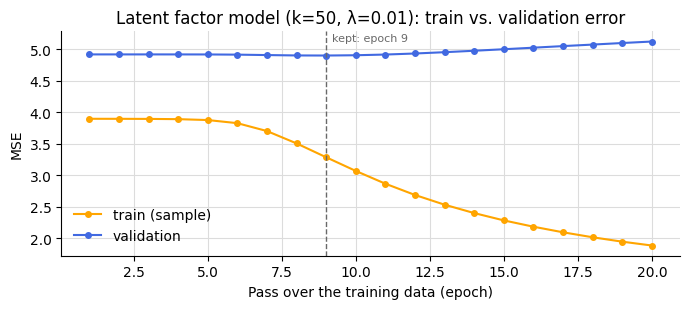

Latent factors (k=50) + full bias model       valid MSE 4.903 | test MSE 5.400


In [26]:
start_time = time.time()
(best_valid, user_vectors, beer_vectors, best_epoch), latent_history = train_latent_factors(
    best_k, best_reg, residual_train, base_train, base_valid, epochs=20, verbose=True)
latent_seconds = time.time() - start_time

figure, axis = plt.subplots(figsize=(7, 3.2))
axis.plot(latent_history["epoch"], latent_history["train MSE"], color=second_color, marker="o", markersize=4, label="train (sample)")
axis.plot(latent_history["epoch"], latent_history["valid MSE"], color=main_color, marker="o", markersize=4, label="validation")
axis.axvline(best_epoch, color=text_color, linewidth=1, linestyle="--")
axis.text(best_epoch + 0.2, axis.get_ylim()[1] * 0.995, f"kept: epoch {best_epoch}", va="top", fontsize=8, color=text_color)
axis.set_xlabel("Pass over the training data (epoch)")
axis.set_ylabel("MSE")
axis.set_title(f"Latent factor model (k={best_k}, λ={best_reg}): train vs. validation error")
axis.legend(frameon=False)
plt.tight_layout()
plt.show()

latent_name = f"Latent factors (k={best_k}) + full bias model"
record(latent_name,
       latent_prediction(base_train, u_train, i_train, user_vectors, beer_vectors),
       latent_prediction(base_valid, u_valid, i_valid, user_vectors, beer_vectors),
       latent_prediction(base_test, u_test, i_test, user_vectors, beer_vectors), latent_seconds)

- Training error keeps going down, but the validation error is lowest after 9 passes and then goes up. After that point, the model is overfitting, so we keep pass 9.
- k = 50 is barely better than k = 10 (less than 0.005), and the test MSE only drops from 5.407 to 5.400.
- The gain is small. It might be because user × style already captures which styles each user likes, and latent factors can't help new users.

### Step 6. Extra: how much of the score is in the review text?

The models above only use what's known before the review is written. Here, we look at the review text itself to see how much of the score shows up in the words. This can't be used to predict scores for beers someone hasn't tried yet since the text only exists after the review. We use ridge regression (linear regression with a penalty). These are the three ways we use to turn text into numbers:
1. Bag of words: which of the 5,000 most common words appear.
2. TF-IDF: the same words, but common words like "the" count less.
3. TF-IDF with word pairs: 20,000 words and phrases like "not bad".

In [27]:
text_representations = {
    "Bag of words (5,000 words)": CountVectorizer(max_features=5000, binary=True),
    "TF-IDF (5,000 words)": TfidfVectorizer(max_features=5000, sublinear_tf=True),
    "TF-IDF (20,000 words + word pairs)": TfidfVectorizer(max_features=20000, ngram_range=(1, 2), min_df=5, sublinear_tf=True),
}
y_text = {}
for part_name in ["train", "valid", "test"]:
    y_text[part_name] = text_sample[part_name]["overall"].to_numpy(float)

text_rows = []
for name, vectorizer in text_representations.items():
    start_time = time.time()
    # Learn the vocabulary on training texts only, then turn every part into a word matrix
    X_text = {"train": vectorizer.fit_transform(text_sample["train"]["text"])}
    X_text["valid"] = vectorizer.transform(text_sample["valid"]["text"])
    X_text["test"] = vectorizer.transform(text_sample["test"]["text"])
    # Format for "best" is (validation MSE, alpha, fitted model)
    best = None
    for alpha in [0.3, 1, 3, 10, 30]:
        ridge = Ridge(alpha=alpha).fit(X_text["train"], y_text["train"])
        valid_mse = mse(y_text["valid"], ridge.predict(X_text["valid"]))
        if best is None or valid_mse < best[0]:
            best = (valid_mse, alpha, ridge)
    test_mse = mse(y_text["test"], np.clip(best[2].predict(X_text["test"]), 1, 20))
    text_rows.append({"representation": name, "chosen α": best[1], "valid MSE": round(best[0], 3),
                      "test MSE": round(test_mse, 3), "time (s)": round(time.time() - start_time)})
    if name.startswith("TF-IDF (5,000"):
        tfidf_vocabulary, tfidf_coefficients = vectorizer.get_feature_names_out(), best[2].coef_
text_table = pd.DataFrame(text_rows)
print("Global-mean MSE on the same test reviews:", round(mse(y_text["test"], np.full(len(y_text["test"]), mu)), 3))
display(text_table)

# Words with the most negative and most positive weights in the TF-IDF (5,000 words) model
words = pd.Series(tfidf_coefficients, index=tfidf_vocabulary).sort_values()
display(pd.DataFrame({"pulls the score down": words.index[:12], "weight (down)": words.values[:12].round(1),
                      "pulls the score up": words.index[::-1][:12], "weight (up)": words.values[::-1][:12].round(1)}))

Global-mean MSE on the same test reviews: 9.011


,representation,chosen α,valid MSE,test MSE,time (s)
0,"Bag of words (5,000 words)",30,5.138,5.087,8
1,"TF-IDF (5,000 words)",3,4.624,4.681,4
2,"TF-IDF (20,000 words + word pairs)",3,4.346,4.437,10


,pulls the score down,weight (down),pulls the score up,weight (up)
0,worst,-11.8,perfect,6.3
1,drain,-11.0,excellent,6.0
2,disgusting,-10.3,great,5.8
3,awful,-9.4,delicious,5.7
4,horrible,-8.8,holy,5.7
5,water,-8.8,amazing,5.6
6,nasty,-8.1,fantastic,5.4
7,worse,-7.9,incredible,5.3
8,crap,-7.9,awesome,5.2
9,foul,-7.3,wonderful,5.2


- TF-IDF beats bag of words (4.68 vs. 5.09), and adding word pairs helps again (4.44).
- "Worst", "drain" and "disgusting" pull the score down, and "perfect", "excellent" and "great" push it up.
- The text gets a lower MSE than our best model (4.44 vs. 5.40), but it only exists after the person has tried the beer. The text models were tested on a sample of 50,000 test reviews, so this is a rough comparison.

### Discussion: advantages and disadvantages

| Approach | Numbers learned | Speed | Pros | Cons |
|---|---|---|---|---|
| Baselines: overall, beer, or user average | up to ~110,000 | instant | Simple; works for anything new | Not personalized |
| Bias model: average + user offset + beer offset | ~140,000 | under a second | Easy to fit and explain | Treats users and beers separately |
| Adding beer info (style, brewer, ABV) and time (experience, year) | ~147,000 | under a second | Helps new beers through their style and brewer | Small gains for well-known beers |
| Adding user × style (each user's taste for each style) | ~2.75 million | under a second | Makes predictions more personal | Needs a bigger λ; no help for new users |
| Latent factors on top of the full bias model (k = 50) | ~7 million more | about 40 seconds, plus about 100 seconds to tune | Finds taste patterns on its own | More to tune; overfits fast; small gain here |
| Review text (TF-IDF + ridge) | 20,000 | under 15 seconds each | Most accurate | Only works after the review is written |

The times come from the table at the bottom and the Step 5 and Step 6 outputs.

Challenges we ran into:
- Size: millions of reviews and offsets are too big to solve as one regression, so we update one group at a time and train the latent model in batches.
- Overfitting: we keep the latent model's best pass, and user × style needs a large λ.
- New users and beers: their predictions come from the other parts (e.g., the beer's style and brewer).
- Missing data: a missing ABV gets its own range, and we keep only a sample of the text to save memory.

In [28]:
# MSE and fit time for every model shown above
display(pd.DataFrame(results).round(3))

,model,train MSE,valid MSE,test MSE,fit time (s)
0,Global mean,11.532,9.360,9.088,0.0
1,Beer average,5.483,5.806,6.096,0.0
2,User average,9.778,8.344,8.402,0.0
3,Bias model (user + beer),4.409,5.322,5.864,0.2
4,"Bias + beer metadata (style, brewer, ABV)",4.394,5.050,5.494,0.5
5,"Bias + metadata + time (experience, year)",4.370,5.010,5.479,0.8
6,Bias + metadata + time + user × style,3.874,4.920,5.407,0.9
7,Latent factors (k=50) + full bias model,3.262,4.903,5.400,37.9


## Evaluation